<a href="https://colab.research.google.com/github/salihaliyi73/XAI_for_LGIT_YOLOv5/blob/main/YOLOv5_GradCAM_Gastrointestinal_XAI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!nvidia-smi



Fri Nov 13 06:53:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Please enable GPU in Runtime settings.")


PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [3]:

%cd /content

!git clone https://github.com/ultralytics/yolov5.git

%cd /content/yolov5


/content
Cloning into 'yolov5'...
remote: Enumerating objects: 18881, done.
remote: Counting objects: 100% (415/415), done.
remote: Compressing objects: 100% (77/77), done.
remote: Total 18881 (delta 353), reused 339 (delta 338), pack-reused 18466 (from 2)
Receiving objects: 100% (18881/18881), 17.70 MiB | 23.33 MiB/s, done.
Resolving deltas: 100% (12887/12887), done.
/content/yolov5


In [5]:

%pip install -qr requirements.txt


In [6]:

import torch
import sys

sys.path.insert(0, '/content/yolov5')

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

import models
print("YOLOv5 model modules imported successfully!")


PyTorch: 2.14.1+cu130
CUDA: True
YOLOv5 model modules imported successfully!


UPLOAD TWO FILES: best.pt and lgit.yaml

In [9]:

from google.colab import files

uploaded = files.upload()


Saving best.pt to best (1).pt
Saving Lgit.yaml to Lgit (1).yaml


Move the files into the YOLOv5 directory

In [10]:

import os
import shutil

os.makedirs('/content/weights', exist_ok=True)

shutil.move('/content/best.pt', '/content/weights/best.pt')
shutil.move('/content/Lgit.yaml', '/content/yolov5/data/Lgit.yaml')

print("Files uploaded and organized successfully!")


FileNotFoundError: [Errno 2] No such file or directory: '/content/best.pt'

In [11]:

import os

print("Files in /content:")
print(os.listdir('/content'))


Files in /content:
['.config', 'weights', 'yolov5', 'sample_data']


In [12]:

from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))


Saving best.pt to best (2).pt
Saving Lgit.yaml to Lgit (2).yaml
Uploaded files: ['best (2).pt', 'Lgit (2).yaml']


In [13]:

import os
import shutil

os.makedirs('/content/weights', exist_ok=True)

for filename, destination in [
    ('best.pt', '/content/weights/best.pt'),
    ('Lgit.yaml', '/content/yolov5/data/Lgit.yaml')
]:
    if os.path.exists(filename):
        shutil.move(filename, destination)
        print(filename, "moved successfully")
    else:
        print(filename, "not found in /content")


best.pt moved successfully
Lgit.yaml moved successfully


In [14]:

import os

print("best.pt:", os.path.exists('/content/weights/best.pt'))
print("Lgit.yaml:", os.path.exists('/content/yolov5/data/Lgit.yaml'))


best.pt: True
Lgit.yaml: True


Load your trained YOLOv5 model

In [15]:

import sys
import torch
import os

sys.path.insert(0, '/content/yolov5')

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

print("Selected device:", device)


Selected device: cuda:0


Load your trained checkpoint

In [16]:

weights_path = '/content/weights/best.pt'

# Only load trusted checkpoints that you own.
checkpoint = torch.load(
    weights_path,
    map_location=device,
    weights_only=False
)

print("Checkpoint loaded successfully!")
print("Checkpoint keys:", checkpoint.keys())


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Checkpoint loaded successfully!
Checkpoint keys: dict_keys(['epoch', 'best_fitness', 'model', 'ema', 'updates', 'optimizer', 'wandb_id', 'date'])


Extract the trained model

In [17]:

model = checkpoint.get('ema')

if model is None:
    model = checkpoint['model']

model = model.float().to(device)
model.eval()

print("Model architecture:", type(model))
print("Model loaded successfully!")


Model architecture: <class 'models.yolo.DetectionModel'>
Model loaded successfully!


Check the eight classes

In [19]:

names = model.names

print("Number of classes:", len(names))
print("\nClass names:")

for class_id, class_name in enumerate(names):
    print(class_id, ":", class_name)


Number of classes: 8

Class names:
0 : polyps
1 : cecum
2 : inadequate
3 : normal
4 : impaction
5 : retroflexion
6 : UC
7 : hemorrhoid


Inspect the model architecture

In [20]:

print(model.model)


Sequential(
  (0): Conv(
    (conv): Conv2d(3, 32, kernel_size=(6, 6), stride=(2, 2), padding=(2, 2), bias=False)
    (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (1): Conv(
    (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (2): C3(
    (cv1): Conv(
      (conv): Conv2d(64, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (cv2): Conv(
      (conv): Conv2d(64, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (cv3): Conv(
      (conv):

Perform detection on a sample image

Upload your sample image

In [23]:
from google.colab import files

uploaded = files.upload()

Saving polyp.jpg to polyp (1).jpg


In [25]:
print(list(uploaded.keys()))

['polyp (1).jpg']


In [27]:
import os

for root, dirs, files in os.walk('/content'):
    for file in files:
        if 'polyp' in file.lower():
            print(os.path.join(root, file))

/content/yolov5/polyp (1).jpg
/content/yolov5/polyp.jpg


Check the actual filename

Run YOLOv5 detection

In [28]:
%cd /content/yolov5

!python detect.py \
--weights /content/weights/best.pt \
--source "/content/yolov5/polyp (1).jpg" \
--img 320 \
--conf 0.25 \
--device 0

/content/yolov5
detect: weights=['/content/weights/best.pt'], source=/content/yolov5/polyp (1).jpg, data=data/coco128.yaml, imgsz=[320, 320], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=0, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-570-gcb2f17fd Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 124 layers, 7,031,701 parameters, 0 gradients, 15.8 GFLOPs
image 1/1 /content/yolov5/polyp (1).jpg: 320x320 1 polyps, 5.8ms
Speed: 1.3ms pre-process, 5.8ms inference, 148.8ms NMS per image at shape (1, 3, 320, 320)
Results saved to runs/detect/exp


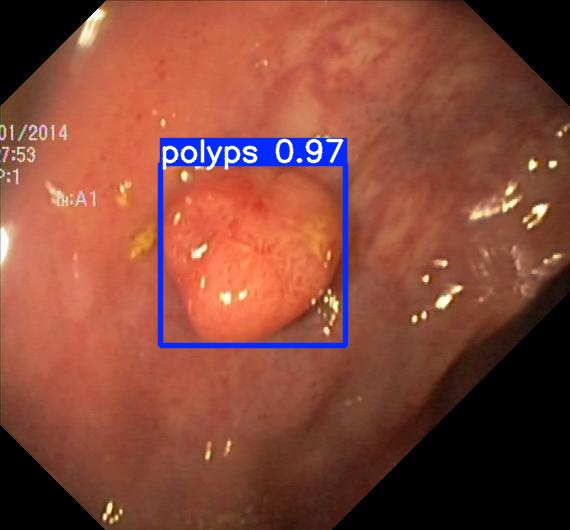

In [29]:
from IPython.display import Image, display

display(Image(filename='/content/yolov5/runs/detect/exp/polyp (1).jpg'))

In [30]:
from google.colab import files

files.download('/content/yolov5/runs/detect/exp/polyp (1).jpg')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# generate a Grad-CAM heatmap for this same image.

In [31]:
model.model[23]

C3(
  (cv1): Conv(
    (conv): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(256, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (cv2): Conv(
    (conv): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(256, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (cv3): Conv(
    (conv): Conv2d(512, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(512, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (m): Sequential(
    (0): Bottleneck(
      (cv1): Conv(
        (conv): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(256, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
     

Prepare the image and inspect the model output

In [32]:
import torch
import cv2
import numpy as np
from utils.augmentations import letterbox

# Image path
image_path = "/content/yolov5/polyp (1).jpg"

# Read image
original_image = cv2.imread(image_path)

if original_image is None:
    raise FileNotFoundError("Image not found!")

# Resize and prepare image
img = letterbox(original_image, 320, stride=32, auto=True)[0]

# Convert BGR to RGB and HWC to CHW
img = img[:, :, ::-1].transpose(2, 0, 1)

# Convert to PyTorch tensor
img = np.ascontiguousarray(img)
img = torch.from_numpy(img).to(device)
img = img.float() / 255.0

# Add batch dimension
img = img.unsqueeze(0)

# Enable gradient calculation
img.requires_grad_(True)

# Forward pass
model.eval()
model.zero_grad()

output = model(img)

print("Output type:", type(output))
print("Number of output elements:", len(output))

for i, item in enumerate(output):
    if isinstance(item, torch.Tensor):
        print(f"Output {i} shape:", item.shape)
    elif isinstance(item, list):
        print(f"Output {i}: list with", len(item), "feature maps")
        for j, feature in enumerate(item):
            print(f"  Feature map {j} shape:", feature.shape)

Output type: <class 'tuple'>
Number of output elements: 2
Output 0 shape: torch.Size([1, 6300, 13])
Output 1: list with 3 feature maps
  Feature map 0 shape: torch.Size([1, 3, 40, 40, 13])
  Feature map 1 shape: torch.Size([1, 3, 20, 20, 13])
  Feature map 2 shape: torch.Size([1, 3, 10, 10, 13])


# Capture feature maps and gradients
Now we will register a hook on our selected layer:

model.model[23]

This layer will provide the feature maps and gradients required for Grad-CAM.

In [33]:
# Storage for activations and gradients
activations = {}
gradients = {}

# Select target layer
target_layer = model.model[23]

# Forward hook: capture feature maps
def forward_hook(module, input, output):
    activations['value'] = output

    # Capture gradients during backpropagation
    output.register_hook(
        lambda grad: gradients.update({'value': grad})
    )

# Register hook
hook = target_layer.register_forward_hook(forward_hook)

print("Grad-CAM hook registered successfully!")
print("Selected layer:", target_layer)

Grad-CAM hook registered successfully!
Selected layer: C3(
  (cv1): Conv(
    (conv): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(256, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (cv2): Conv(
    (conv): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(256, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (cv3): Conv(
    (conv): Conv2d(512, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(512, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (m): Sequential(
    (0): Bottleneck(
      (cv1): Conv(
        (conv): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(256, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (ac

Generate a forward pass and capture activations

In [34]:
# Clear previous stored values
activations.clear()
gradients.clear()

# Forward pass through the model
model.zero_grad()

output = model(img)

# Check captured feature maps
print("Activation shape:", activations['value'].shape)
print("Gradient captured:", 'value' in gradients)
print("Raw prediction shape:", output[0].shape)

Activation shape: torch.Size([1, 512, 10, 10])
Gradient captured: False
Raw prediction shape: torch.Size([1, 6300, 13])


Identify the polyp prediction

In [35]:
# Get raw YOLOv5 predictions
predictions = output[0][0]

# Objectness scores
objectness = predictions[:, 4]

# Polyp class scores (class ID 0)
polyp_scores = predictions[:, 5]

# Combined confidence scores
combined_scores = objectness * polyp_scores

# Find the candidate with the highest polyp score
best_index = torch.argmax(combined_scores)

print("Best candidate index:", best_index.item())
print("Objectness score:", objectness[best_index].item())
print("Polyp class score:", polyp_scores[best_index].item())
print("Combined score:", combined_scores[best_index].item())

Best candidate index: 6044
Objectness score: 0.971444308757782
Polyp class score: 0.9990744590759277
Combined score: 0.9705451726913452


# Calculate Grad-CAM gradients

In [36]:
# Select the polyp candidate score
target_score = combined_scores[best_index]

# Clear previous gradients
model.zero_grad()

# Backpropagation
target_score.backward()

# Check whether gradients were captured
print("Gradient captured:", 'value' in gradients)

if 'value' in gradients:
    print("Gradient shape:", gradients['value'].shape)
    print("Activation shape:", activations['value'].shape)

Gradient captured: True
Gradient shape: torch.Size([1, 512, 10, 10])
Activation shape: torch.Size([1, 512, 10, 10])


We now have both components required for Grad-CAM:
- Activations: [1, 512, 10, 10]
- Gradients: [1, 512, 10, 10]
Now we can calculate the Grad-CAM heatmap.
# Generate the Grad-CAM heatmap

In [37]:
import torch
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Get activations and gradients
acts = activations['value'].detach()
grads = gradients['value'].detach()

# Calculate channel-wise weights using global average pooling
weights = grads.mean(dim=(2, 3), keepdim=True)

# Weighted combination of feature maps
cam = (weights * acts).sum(dim=1)

# Apply ReLU
cam = F.relu(cam)

# Normalize heatmap
cam = cam[0]

cam = cam - cam.min()
cam = cam / (cam.max() + 1e-8)

# Convert to NumPy
cam = cam.cpu().numpy()

print("Grad-CAM heatmap shape:", cam.shape)
print("Minimum value:", cam.min())
print("Maximum value:", cam.max())

Grad-CAM heatmap shape: (10, 10)
Minimum value: 0.0
Maximum value: 0.9999942


# Overlay Grad-CAM on the original image

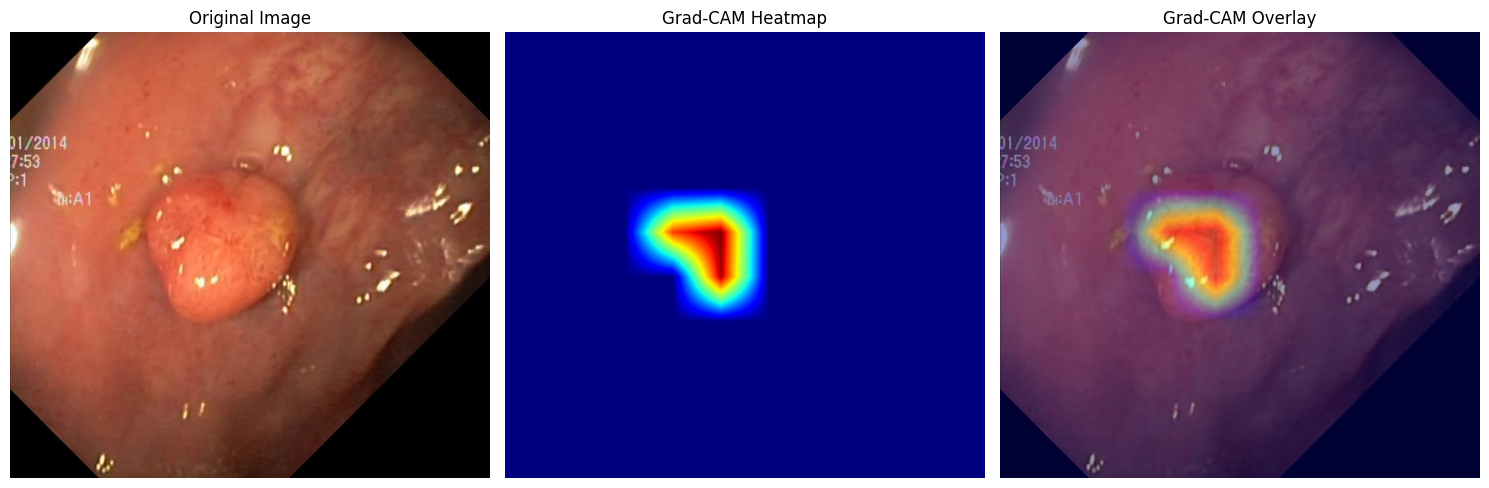

In [38]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load original image
original = cv2.imread("/content/yolov5/polyp (1).jpg")
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

# Resize Grad-CAM to original image dimensions
heatmap = cv2.resize(
    cam,
    (original.shape[1], original.shape[0])
)

# Convert heatmap to color
heatmap_uint8 = np.uint8(255 * heatmap)
heatmap_color = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

# Convert BGR to RGB
heatmap_color = cv2.cvtColor(
    heatmap_color,
    cv2.COLOR_BGR2RGB
)

# Overlay heatmap on original image
overlay = cv2.addWeighted(
    original, 0.6,
    heatmap_color, 0.4,
    0
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Download

In [39]:
from google.colab import files
import cv2

# Save the Grad-CAM overlay
cv2.imwrite(
    "/content/yolov5/GradCAM_Overlay.jpg",
    cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR)
)

# Save the heatmap
cv2.imwrite(
    "/content/yolov5/GradCAM_Heatmap.jpg",
    heatmap_uint8
)

# Download both files
files.download("/content/yolov5/GradCAM_Overlay.jpg")
files.download("/content/yolov5/GradCAM_Heatmap.jpg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

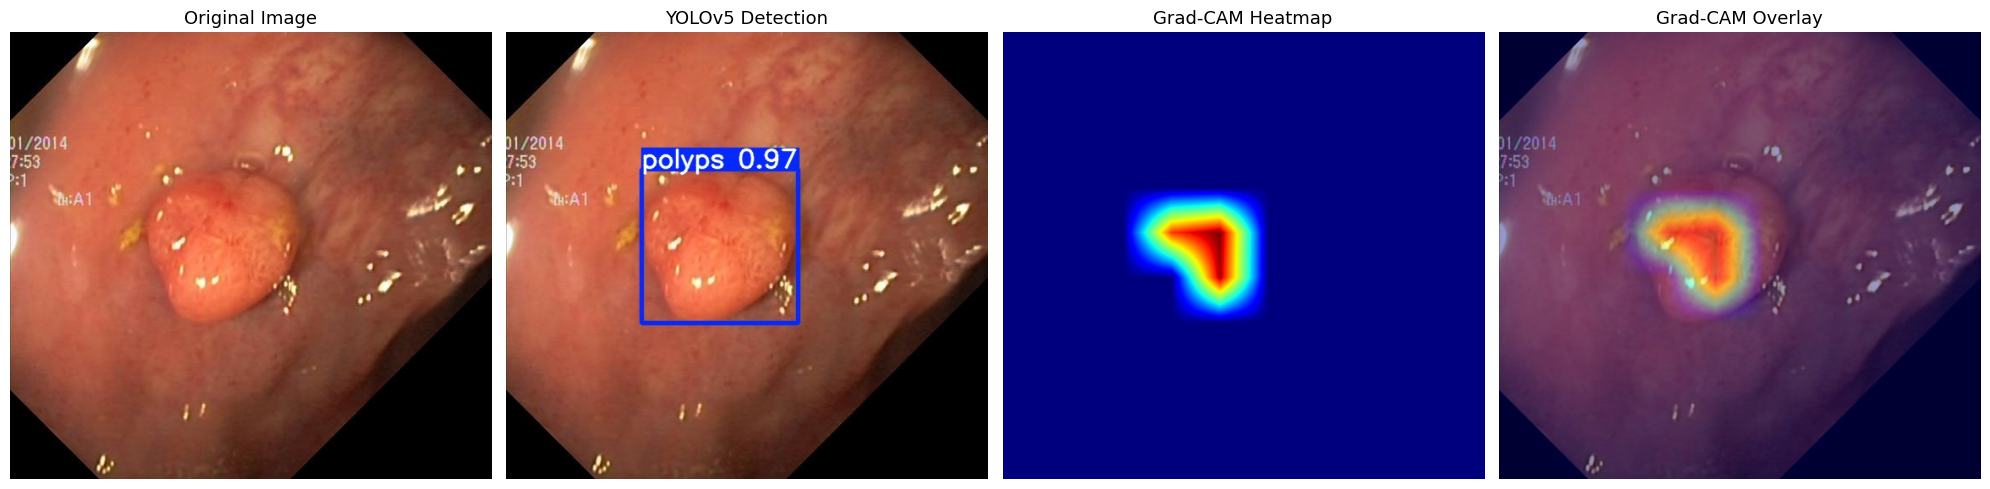

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files

# Load original image
original = cv2.imread("/content/yolov5/polyp (1).jpg")
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

# Load YOLOv5 detection result
detection = cv2.imread(
    "/content/yolov5/runs/detect/exp/polyp (1).jpg"
)
detection = cv2.cvtColor(detection, cv2.COLOR_BGR2RGB)

# Create horizontal comparison
plt.figure(figsize=(20, 5))

images = [original, detection, heatmap, overlay]
titles = [
    "Original Image",
    "YOLOv5 Detection",
    "Grad-CAM Heatmap",
    "Grad-CAM Overlay"
]

for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(images[i], cmap="jet" if i == 2 else None)
    plt.title(titles[i], fontsize=13)
    plt.axis("off")

plt.tight_layout()

# Save as high-resolution image
plt.savefig(
    "/content/yolov5/Complete_GradCAM_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Download the final figure
files.download(
    "/content/yolov5/Complete_GradCAM_Comparison.png"
)